# 01 · Exploratory Data Analysis: `application_train`

**Goal of this notebook:** understand the main application table before building any model,
and collect the first evidence for the hypotheses written in the README:

| # | Question | What EDA can already tell us |
|---|---|---|
| H1 | Non-linearity | Does default rate change *linearly* with key features? |
| H2 | Missing data | Is *missingness itself* related to default? |
| H4 | Class imbalance | How rare are defaults, and what does that do to naive metrics? |

The six history tables (bureau, previous applications, installments, …) are explored in a later notebook.

In [1]:
import sys
sys.path.insert(0, "..")  # make `src/` importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load, mem_mb
from src.viz import set_style, save, BLUE, ORANGE, INK_2, GRID, SURFACE

set_style()
pd.set_option("display.max_columns", 50)

## 0 · Load
`load()` reads the CSV and downcasts dtypes (float64 → float32, text → category), which cuts memory by ~70%.

In [2]:
train = load("application_train")
print(f"{train.shape[0]:,} applications × {train.shape[1]} columns  |  {mem_mb(train):.0f} MB in memory")
print(train.dtypes.map(lambda d: d.name).value_counts().to_string())

307,511 applications × 122 columns  |  95 MB in memory
float32     65
int8        37
category    16
int32        2
int16        2


## 1 · The target: how rare is "payment difficulty"?
`TARGET = 1` means the client was late by more than X days on at least one of the first Y instalments
(X and Y are not disclosed). It is a *payment difficulty* flag, not a write-off.

In [3]:
counts = train["TARGET"].value_counts().sort_index()
summary = pd.DataFrame({"clients": counts, "share": (counts / counts.sum()).map("{:.2%}".format)})
summary.index = ["0 · repaid without difficulty", "1 · payment difficulty"]
summary

,clients,share
0 · repaid without difficulty,282686,91.93%
1 · payment difficulty,24825,8.07%


**Why accuracy is useless here:** a "model" that predicts *nobody* will default is right ~92% of the time
and catches zero risky clients. We will therefore judge models by how well they **rank** clients
(ROC-AUC, PR-AUC) and how trustworthy their probabilities are (calibration), never by accuracy.

In [4]:
base_rate = train["TARGET"].mean()
print(f"Accuracy of 'predict 0 for everyone': {1 - base_rate:.2%}")
print(f"Risky clients it catches:             0 of {int(train['TARGET'].sum()):,}")

Accuracy of 'predict 0 for everyone': 91.93%
Risky clients it catches:             0 of 24,825


## 2 · Missing data: the big picture
Before treating missing values as a nuisance, look at *how much* is missing and *where*.

In [5]:
miss = train.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
bins = pd.cut(miss, [0, 0.01, 0.10, 0.50, 1.0], labels=["< 1%", "1–10%", "10–50%", "> 50%"])
print(f"{len(miss)} of {train.shape[1]} columns have missing values")
print(bins.value_counts().sort_index().rename("columns").to_string())

67 of 122 columns have missing values
< 1%      10
1–10%      0
10–50%    16
> 50%     41


In [6]:
miss.head(15).map("{:.1%}".format).rename("missing share").to_frame()

,missing share
COMMONAREA_MEDI,69.9%
COMMONAREA_AVG,69.9%
COMMONAREA_MODE,69.9%
NONLIVINGAPARTMENTS_MODE,69.4%
NONLIVINGAPARTMENTS_AVG,69.4%
NONLIVINGAPARTMENTS_MEDI,69.4%
FONDKAPREMONT_MODE,68.4%
LIVINGAPARTMENTS_MODE,68.4%
LIVINGAPARTMENTS_AVG,68.4%
LIVINGAPARTMENTS_MEDI,68.4%


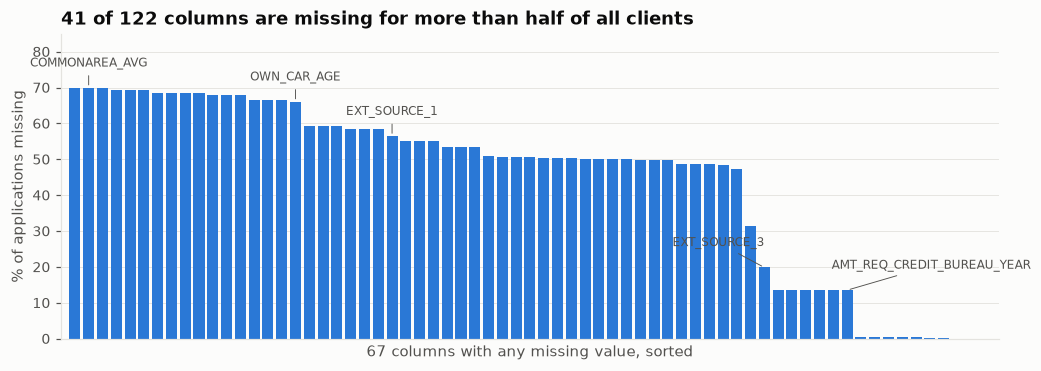

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(range(len(miss)), miss.values * 100, color=BLUE, width=0.8)
ax.set_xlim(-1, len(miss))
ax.set_xticks([])
ax.set_ylabel("% of applications missing")
ax.set_xlabel(f"{len(miss)} columns with any missing value, sorted")
ax.set_title(f"{(miss > 0.5).sum()} of {train.shape[1]} columns are missing for more than half of all clients")
for name, dx in [("COMMONAREA_AVG", 0), ("OWN_CAR_AGE", 0), ("EXT_SOURCE_1", 0),
                 ("EXT_SOURCE_3", -30), ("AMT_REQ_CREDIT_BUREAU_YEAR", 55)]:
    i = miss.index.get_loc(name)
    ax.annotate(name, (i, miss.iloc[i] * 100), xytext=(dx, 14), textcoords="offset points",
                ha="center", fontsize=8, color=INK_2, arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.6))
ax.set_ylim(0, 85)
save(fig, "eda_missing_share")
plt.show()

### Missing-data map: do columns go missing *together*?
Each row of the image is one client (random sample of 1,000, sorted by how many values they miss),
each column is a feature (sorted as above). Blue = missing.

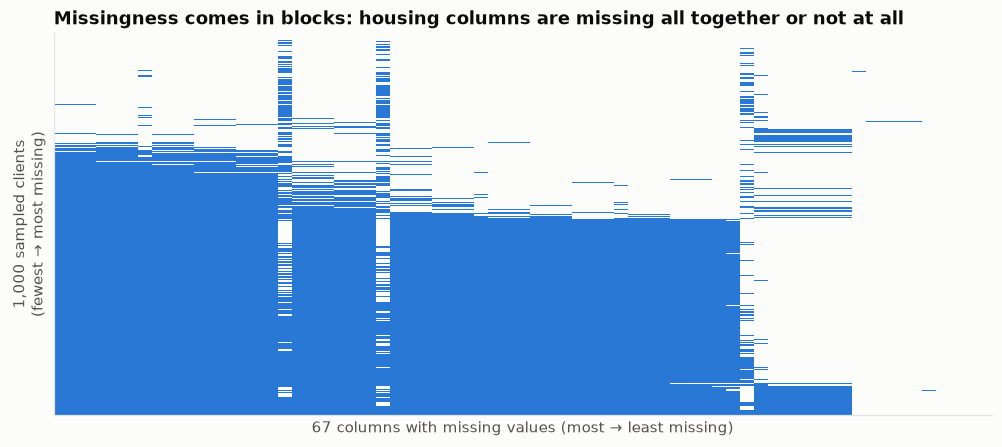

In [8]:
cols = miss.index
sample = train[cols].sample(1000, random_state=42)
mask = sample.isna()
mask = mask.loc[mask.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(11, 4.5))
cmap = plt.matplotlib.colors.ListedColormap([SURFACE, BLUE])
ax.imshow(mask.values, aspect="auto", cmap=cmap, interpolation="nearest")
ax.grid(False)
ax.set_yticks([])
ax.set_ylabel("1,000 sampled clients\n(fewest → most missing)")
ax.set_xticks([])
ax.set_xlabel(f"{len(cols)} columns with missing values (most → least missing)")
ax.set_title("Missingness comes in blocks: housing columns are missing all together or not at all")
save(fig, "eda_missing_map")
plt.show()

Which columns make up that block? The names share suffixes `_AVG`, `_MODE`, `_MEDI`: normalised
statistics about the client's **building** (size, age, floors, common area …).

In [9]:
housing = [c for c in train.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
other = [c for c in cols if c not in housing]
print(f"Housing columns: {len(housing)}  |  missing share range: "
      f"{train[housing].isna().mean().min():.0%} – {train[housing].isna().mean().max():.0%}")
row_share = train[housing].isna().mean(axis=1)
print(f"Clients missing ALL housing columns: {(row_share == 1).mean():.1%}")
print(f"Clients missing NONE of them:        {(row_share == 0).mean():.1%}")
print(f"\nOther columns with missing values ({len(other)}):")
print(train[other].isna().mean().sort_values(ascending=False).map("{:.1%}".format).to_string())

Housing columns: 47  |  missing share range: 47% – 70%
Clients missing ALL housing columns: 47.4%
Clients missing NONE of them:        25.6%

Other columns with missing values (20):
OWN_CAR_AGE                   66.0%
EXT_SOURCE_1                  56.4%
OCCUPATION_TYPE               31.3%
EXT_SOURCE_3                  19.8%
AMT_REQ_CREDIT_BUREAU_HOUR    13.5%
AMT_REQ_CREDIT_BUREAU_DAY     13.5%
AMT_REQ_CREDIT_BUREAU_WEEK    13.5%
AMT_REQ_CREDIT_BUREAU_MON     13.5%
AMT_REQ_CREDIT_BUREAU_QRT     13.5%
AMT_REQ_CREDIT_BUREAU_YEAR    13.5%
NAME_TYPE_SUITE                0.4%
OBS_30_CNT_SOCIAL_CIRCLE       0.3%
DEF_30_CNT_SOCIAL_CIRCLE       0.3%
OBS_60_CNT_SOCIAL_CIRCLE       0.3%
DEF_60_CNT_SOCIAL_CIRCLE       0.3%
EXT_SOURCE_2                   0.2%
AMT_GOODS_PRICE                0.1%
AMT_ANNUITY                    0.0%
CNT_FAM_MEMBERS                0.0%
DAYS_LAST_PHONE_CHANGE         0.0%
